# ShiftQ
Sensitivity-Aware Mixed-Precision Quantization and Adaptive LoRA Fine-Tuning for Large Language Models

## 1. Research Question
Can adaptive bits and ranks improve perplexity at the storage budget of 4-bit/rank-16 LoRA?

[LoRA](https://arxiv.org/abs/2106.09685), [QLoRA](https://arxiv.org/abs/2305.14314), [LQ-LoRA](https://arxiv.org/abs/2311.12023), and [AutoQRA](https://arxiv.org/abs/2602.22268) are prior work.
ShiftQ is a greedy research heuristic, with no novelty claim; source notes are in `results/literature.csv`.

## 2. Setup and Imports
Use the README environment. The MLX affine baseline is QLoRA-style, not an NF4 reproduction.

In [1]:
import os, gc, json, time, hashlib, platform, inspect
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
os.environ.setdefault("HF_HOME", str(Path(".cache/huggingface").resolve()))
os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
from mlx.utils import tree_flatten, tree_unflatten, tree_map
from mlx_lm import load
from mlx_lm.utils import load_tokenizer
from mlx_lm.tuner.lora import LoRALinear
from mlx_lm.tuner.trainer import grad_checkpoint

/Users/amithkm/Documents/shiftQ/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from datasets import load_dataset
from huggingface_hub import snapshot_download
from tqdm.auto import tqdm
from IPython.display import display, Markdown
assert mx.metal.is_available(), "Metal is required."
print(inspect.signature(load))
print(inspect.signature(nn.quantize))
print(inspect.signature(LoRALinear.from_base))

(path_or_hf_repo: str, tokenizer_config: Optional[Dict[str, Any]] = None, model_config: Optional[Dict[str, Any]] = None, adapter_path: Optional[str] = None, lazy: bool = False, return_config: bool = False, revision: Optional[str] = None, trust_remote_code: bool = False) -> Union[Tuple[mlx.nn.layers.base.Module, mlx_lm.tokenizer_utils.TokenizerWrapper], Tuple[mlx.nn.layers.base.Module, mlx_lm.tokenizer_utils.TokenizerWrapper, Dict[str, Any]]]
(model: mlx.nn.layers.base.Module, group_size: int = None, bits: int = None, *, mode: str = 'affine', quantize_input: bool = False, class_predicate: Optional[Callable[[str, mlx.nn.layers.base.Module], Union[bool, dict]]] = None)
(linear: mlx.nn.layers.linear.Linear, r: int = 8, dropout: float = 0.0, scale: float = 20.0)


## 3. Model Configuration
Full mode requires opt-in. TRAIN_STEPS counts optimizer updates, each with four microbatches.

In [ ]:
SMOKE_MODEL = "Qwen/Qwen3-0.6B-Base"
MAIN_MODEL = "Qwen/Qwen3-1.7B-Base"
LARGE_MODEL = "Qwen/Qwen3-4B-Base"
FAST_MODE = False
MODEL_ID = MAIN_MODEL
SEED = 42
MAX_LENGTH = 256
BATCH_SIZE = 1

In [ ]:
ALLOW_FULL_RUN = True
assert FAST_MODE or ALLOW_FULL_RUN, "Full experiments require opt-in."
LEARNING_RATE = 1e-4
GRAD_ACCUM = 4
TRAIN_STEPS = 150
GROUP_SIZE, LORA_SCALE = 64, 2.0
CHECKPOINT = not FAST_MODE
SEEDS = [SEED] if FAST_MODE else [SEED, SEED + 1]

In [6]:
counts = [4, 64, 8, 8, 4, 8] if FAST_MODE else [32, 512, 64, 64, 32, 64]
keys = ["calibration", "train", "validation", "test", "ag_calibration", "ag_test"]
COUNTS = dict(zip(keys, counts))
RUN_SHIFT = not FAST_MODE
RUN_ABLATIONS = not FAST_MODE
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT, FIG = Path("results") / RUN_ID, Path("figures") / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

In [7]:
def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False))

packages = ["mlx", "mlx-lm", "datasets", "transformers", "numpy", "pandas", "matplotlib"]
versions = {name: version(name) for name in packages}
np.random.seed(SEED)
mx.random.seed(SEED)
print(versions)

{'mlx': '0.32.4', 'mlx-lm': '0.32.2', 'datasets': '5.1.0', 'transformers': '5.20.1', 'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


In [8]:
settings = ["MODEL_ID", "FAST_MODE", "SEED", "SEEDS", "MAX_LENGTH", "BATCH_SIZE",
            "GROUP_SIZE", "LORA_SCALE", "LEARNING_RATE", "GRAD_ACCUM", "TRAIN_STEPS",
            "CHECKPOINT", "RUN_SHIFT", "RUN_ABLATIONS", "COUNTS"]
metadata = {key: globals()[key] for key in settings}
metadata.update(versions=versions, python=platform.python_version(),
                machine=platform.platform(), adapter_dtype="float32")
save_json(OUT / "environment.json", metadata)

## 4. Dataset Preparation
Deduplicate rows before packing disjoint token blocks. Calibration uses training splits only; AG News test text is held out.

In [9]:
REVISIONS = {
    'Qwen/Qwen3-0.6B-Base': 'da87bfb608c14b7cf20ba1ce41287e8de496c0cd',
    'Qwen/Qwen3-1.7B-Base': 'ea980cb0a6c2ae4b936e82123acc929f1cec04c1',
    'Qwen/Qwen3-4B-Base': '906bfd4b4dc7f14ee4320094d8b41684abff8539'}
REVISION = REVISIONS[MODEL_ID]

In [10]:
MODEL_PATH = snapshot_download(MODEL_ID, revision=REVISION,
    allow_patterns=["*.json", "*.safetensors", "*.txt", "*.model"])
tokenizer = load_tokenizer(Path(MODEL_PATH))
metadata["model_revision"] = REVISION
save_json(OUT / "environment.json", metadata)

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 2206.20it/s]


In [11]:
WIKI_REV = "b08601e04326c79dfdd32d625aee71d232d685c3"
AG_REV = "eb185aade064a813bc0b7f42de02595523103ca4"
wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", revision=WIKI_REV)
ag = load_dataset("fancyzhx/ag_news", revision=AG_REV)
seen, provenance = set(), {}
rng = np.random.default_rng(SEED)

In [12]:
def unique_rows(dataset):
    for index in rng.permutation(len(dataset)):
        text = dataset[int(index)]["text"].strip()
        digest = hashlib.sha256(" ".join(text.split()).encode()).hexdigest()
        if text and digest not in seen:
            seen.add(digest)
            yield text, dict(row=int(index), sha256=digest)

In [13]:
def make_sequences(dataset, count, label):
    tokens, rows, needed = [], [], count * (MAX_LENGTH + 1)
    for text, info in unique_rows(dataset):
        rows.append(info)
        tokens.extend(tokenizer.encode(text, add_special_tokens=False) + [tokenizer.eos_token_id])
        if len(tokens) >= needed:
            break
    provenance[label] = rows
    return np.array(tokens[:needed], dtype=np.int32).reshape(count, MAX_LENGTH + 1)

In [14]:
sources = dict(calibration=wiki["train"], train=wiki["train"],
               validation=wiki["validation"], test=wiki["test"],
               ag_calibration=ag["train"], ag_test=ag["test"])
data = {key: make_sequences(sources[key], n, key) for key, n in COUNTS.items()}
hashes = [{hashlib.sha256(row.tobytes()).hexdigest() for row in v} for v in data.values()]
assert all(len(h) == len(v) for h, v in zip(hashes, data.values()))
assert sum(map(len, hashes)) == len(set.union(*hashes)), "Repeated sequences"
np.savez_compressed(OUT / "sequences.npz", **data)

In [15]:
save_json(OUT / "data.json", dict(wiki_revision=WIKI_REV, ag_revision=AG_REV,
    config="wikitext-2-raw-v1", seed=SEED, counts=COUNTS, source_rows=provenance,
    fingerprints={k: v._fingerprint for k, v in sources.items()}))
display(pd.DataFrame({k: [len(v), v.shape[1] - 1] for k, v in data.items()},
                     index=["sequences", "prediction_tokens"]).T)
del wiki, ag, sources

,sequences,prediction_tokens
calibration,32,256
train,512,256
validation,64,256
test,64,256
ag_calibration,32,256
ag_test,64,256


## 5. Full-Precision Baseline
Keep the original checkpoint dtype (BF16). Stored tensor bytes and MLX allocator memory are separate measurements; neither is process RSS.

In [16]:
def fresh_model():
    model, _ = load(MODEL_PATH)
    model.eval()
    mx.eval(model.parameters())
    return model

In [17]:
def storage_bytes(model):
    return sum(value.nbytes for _, value in tree_flatten(model.parameters()))

def clean_memory():
    gc.collect()
    mx.clear_cache()

In [18]:
def loss_fn(model, batch):
    logits = model(batch[:, :-1]).astype(mx.float32)
    return nn.losses.cross_entropy(logits, batch[:, 1:], reduction="mean")

In [19]:
def evaluate(model, sequences):
    model.eval()
    losses = []
    for start in range(0, len(sequences), BATCH_SIZE):
        batch = mx.array(sequences[start:start + BATCH_SIZE])
        losses.extend([loss_fn(model, batch).item()] * len(batch))
    assert np.isfinite(losses).all(), "Non-finite loss"
    return float(np.mean(losses))

In [20]:
def timed_forward(model, batch):
    mx.synchronize()
    start = time.perf_counter()
    mx.eval(model(batch))
    mx.synchronize()
    return 1000 * (time.perf_counter() - start)

In [21]:
def latency(model, sequences):
    batch = mx.array(sequences[:BATCH_SIZE, :-1])
    for _ in range(2):
        timed_forward(model, batch)
    return float(np.median([timed_forward(model, batch) for _ in range(5)]))

In [22]:
def held_out_metrics(model):
    row = {}
    for key in ["validation", "test", "ag_test"]:
        nll = evaluate(model, data[key])
        row[key + "_nll"], row[key + "_ppl"] = nll, float(np.exp(nll))
    return row

In [23]:
def precision_metrics(model):
    types = (nn.QuantizedLinear, nn.QuantizedEmbedding)
    layers = [m for _, m in model.named_modules() if isinstance(m, types)]
    weights = sum(m.weight.size * 32 // m.bits for m in layers)
    packed = sum(m.weight.nbytes for m in layers)
    return dict(effective_bpw=storage_bytes(model) * 8 / BASE_PARAMS,
                quantized_weight_bpw=8 * packed / weights if weights else None)

In [24]:
def measure(model):
    clean_memory()
    mx.reset_peak_memory()
    loaded = mx.get_active_memory() / 1e9
    row = held_out_metrics(model)
    row.update(model_mb=storage_bytes(model) / 1e6, loaded_mlx_gb=loaded,
               latency_ms=latency(model, data["validation"]))
    row["inference_peak_gb"] = mx.get_peak_memory() / 1e9
    return dict(row, **precision_metrics(model))

In [25]:
results = []
def record(name, seed, metrics):
    row = dict(training_peak_gb=None, training_time_s=None, trainable_params=0)
    row.update(method=name, seed=seed, model=MODEL_ID, **metrics)
    folder = OUT / f"{name}_{seed}"
    folder.mkdir(parents=True, exist_ok=True)
    save_json(folder / "metrics.json", row)
    results.append(row)
    pd.DataFrame(results).to_csv(OUT / "metrics.csv", index=False)

In [26]:
model = fresh_model()
BASE_PARAMS = sum(w.size for _, w in tree_flatten(model.parameters()))
base_dtype = str(next(iter(dict(tree_flatten(model.parameters())).values())).dtype)
print("Checkpoint dtype:", base_dtype)
base_metrics = measure(model)

Checkpoint dtype: mlx.core.bfloat16


In [27]:
base_metrics.update(effective_bpw=8e6 * base_metrics["model_mb"] / BASE_PARAMS,
                    checkpoint_dtype=base_dtype)
record("unquantized", SEED, base_metrics)
display(pd.DataFrame([base_metrics]))
del model
clean_memory()

,validation_nll,validation_ppl,test_nll,test_ppl,ag_test_nll,ag_test_ppl,model_mb,loaded_mlx_gb,latency_ms,inference_peak_gb,effective_bpw,quantized_weight_bpw,checkpoint_dtype
0,3.359009,28.760662,3.228604,25.244399,3.501076,33.151117,1192.09984,1.1921,53.792,1.811875,16.0,None,mlx.core.bfloat16


## 6. Uniform Quantization
Probe 3/4/6/8-bit kernels. Use group size 64; record unsupported shapes.

In [28]:
def probe_bits(bits):
    layer = nn.Linear(128, 64, bias=False)
    quant = nn.QuantizedLinear.from_linear(layer, GROUP_SIZE, bits)
    restored = mx.dequantize(quant.weight, quant.scales, quant.biases,
                            group_size=GROUP_SIZE, bits=bits)
    mx.eval(restored, quant(mx.ones((1, 128))))
    return bits

In [29]:
SUPPORTED, failures = [], {}
for bits in [3, 4, 6, 8]:
    try:
        SUPPORTED.append(probe_bits(bits))
    except (ValueError, RuntimeError) as error:
        failures[str(bits)] = str(error)
assert 4 in SUPPORTED, "The 4-bit baseline is required"
save_json(OUT / "supported_bits.json", dict(supported=SUPPORTED, failures=failures))
print(SUPPORTED)

[3, 4, 6, 8]


In [30]:
def quantizable(module):
    return (hasattr(module, "to_quantized") and hasattr(module, "weight")
            and module.weight.ndim == 2 and module.weight.shape[-1] % GROUP_SIZE == 0)

In [31]:
def quantize(model, mapping=None, default_bits=4):
    mapping = mapping or {}
    def predicate(name, module):
        if not quantizable(module):
            return False
        return dict(bits=mapping.get(name, default_bits), group_size=GROUP_SIZE)
    nn.quantize(model, class_predicate=predicate)
    mx.eval(model.parameters())

In [32]:
def uniform_run(bits):
    model = fresh_model()
    quantize(model, default_bits=bits)
    metrics = measure(model)
    metrics["effective_bpw"] = storage_bytes(model) * 8 / BASE_PARAMS
    record(f"uniform_{bits}bit", SEED, metrics)
    del model
    clean_memory()

In [33]:
for bits in ([4] if FAST_MODE else SUPPORTED):
    uniform_run(bits)
uniform = pd.DataFrame(results)
display(uniform[["method", "validation_ppl", "model_mb", "latency_ms"]])

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=160)
    plt.show()

,method,validation_ppl,model_mb,latency_ms
0,unquantized,28.760662,1192.099840,53.792000
1,uniform_3bit,98.409301,260.874240,52.956000
2,uniform_4bit,36.472063,335.372288,52.681792
3,uniform_6bit,29.376103,484.368384,53.547417
4,uniform_8bit,28.899299,633.364480,52.710125


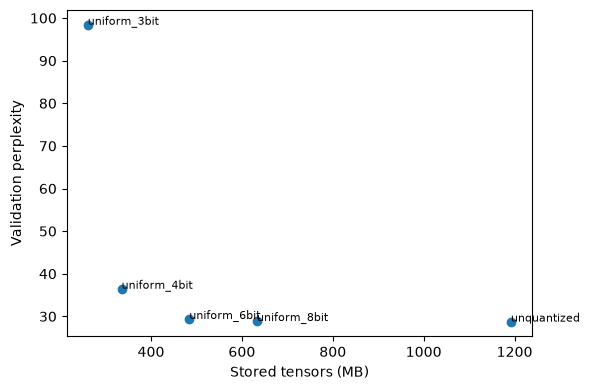

In [34]:
plt.figure(figsize=(6, 4))
plt.scatter(uniform.model_mb, uniform.validation_ppl)
for row in uniform.itertuples():
    plt.annotate(row.method, (row.model_mb, row.validation_ppl), fontsize=8)
plt.xlabel("Stored tensors (MB)")
plt.ylabel("Validation perplexity")
save_figure("uniform_tradeoff")

## 7. Layer Sensitivity
Measure $E_i(b)=\|W_i-\hat W_i(b)\|_F^2/(\|W_i\|_F^2+10^{-12})$.
The optional activation-weighted score ignores cross-channel covariance.

In [35]:
model = fresh_model()
modules = dict(model.named_modules())
projections = {name: layer for name, layer in modules.items()
               if ".layers." in name and isinstance(layer, nn.Linear) and quantizable(layer)}
assert projections, "No supported transformer projections"
shapes = {name: tuple(layer.weight.shape) for name, layer in projections.items()}
skipped = [n for n, m in modules.items() if hasattr(m, "to_quantized") and not quantizable(m)]
save_json(OUT / "skipped_modules.json", skipped)

In [36]:
shape_table = pd.DataFrame([dict(name=n, output=s[0], input=s[1],
    layer=int(n.split("layers.")[1].split(".")[0]), projection=n.rsplit(".", 1)[-1])
    for n, s in shapes.items()]).set_index("name")
display(shape_table.head(7))

,output,input,layer,projection
name,,,,
model.layers.27.mlp.up_proj,3072,1024,27,up_proj
model.layers.27.mlp.down_proj,1024,3072,27,down_proj
model.layers.27.mlp.gate_proj,3072,1024,27,gate_proj
model.layers.27.self_attn.o_proj,1024,2048,27,o_proj
model.layers.27.self_attn.v_proj,1024,1024,27,v_proj
model.layers.27.self_attn.k_proj,1024,1024,27,k_proj
model.layers.27.self_attn.q_proj,2048,1024,27,q_proj


In [37]:
name = next(iter(projections))
weight = projections[name].weight
packed = mx.quantize(weight, group_size=GROUP_SIZE, bits=4)
restored = mx.dequantize(*packed, group_size=GROUP_SIZE, bits=4)
error = mx.sum((weight.astype(mx.float32) - restored.astype(mx.float32)) ** 2)
error /= mx.sum(weight.astype(mx.float32) ** 2) + 1e-12
print(name, weight.shape, "normalized error:", error.item())
del weight, packed, restored, error

model.layers.27.mlp.up_proj (3072, 1024) normalized error: 0.008621732704341412


In [38]:
class Capture(nn.Module):
    def __init__(self, base, name):
        super().__init__()
        self.base, self.name = base, name

    def __call__(self, x):
        moment = mx.mean(x.astype(mx.float32) ** 2, axis=tuple(range(x.ndim - 1)))
        activation_stats[self.name] = activation_stats.get(self.name, 0) + moment
        return self.base(x)

In [39]:
def collect_moments(model, sequences):
    global activation_stats
    activation_stats = {}
    replacements = [(n, Capture(layer, n)) for n, layer in projections.items()]
    model.update_modules(tree_unflatten(replacements))
    try:
        return run_calibration(model, sequences)
    finally:
        model.update_modules(tree_unflatten(list(projections.items())))

In [40]:
def run_calibration(model, sequences):
    for row in tqdm(sequences, desc="Calibration"):
        mx.eval(model(mx.array(row[None, :-1])), activation_stats)
    return {name: value / len(sequences) for name, value in activation_stats.items()}

moments = {}
if RUN_SHIFT:
    moments["wiki"] = collect_moments(model, data["calibration"])
    moments["ag"] = collect_moments(model, data["ag_calibration"])

Calibration: 100%|██████████| 32/32 [00:01<00:00, 16.18it/s]


In [41]:
def reconstruction(layer, bits):
    packed = mx.quantize(layer.weight, group_size=GROUP_SIZE, bits=bits)
    restored = mx.dequantize(*packed, group_size=GROUP_SIZE, bits=bits).astype(mx.float32)
    weight = layer.weight.astype(mx.float32)
    delta = mx.sum((weight - restored) ** 2, axis=0)
    norm = mx.sum(weight ** 2, axis=0)
    return delta, norm, sum(x.nbytes for x in packed)

In [42]:
def projection_scores(name, layer, bits):
    delta, norm, size = reconstruction(layer, bits)
    row = dict(name=name, bits=bits, bytes=size)
    weights = {"error": mx.ones_like(norm)}
    weights.update({key: stats[name] for key, stats in moments.items()})
    for key, weight in weights.items():
        row[key] = ((delta * weight).sum() / ((norm * weight).sum() + 1e-12)).item()
    return row

In [43]:
scores = pd.DataFrame([projection_scores(n, m, b) for n, m in tqdm(projections.items())
                       for b in SUPPORTED])
scores.to_csv(OUT / "sensitivity.csv", index=False)
q4 = scores.query("bits == 4").set_index("name").join(shape_table)

100%|██████████| 196/196 [00:00<00:00, 209.14it/s]


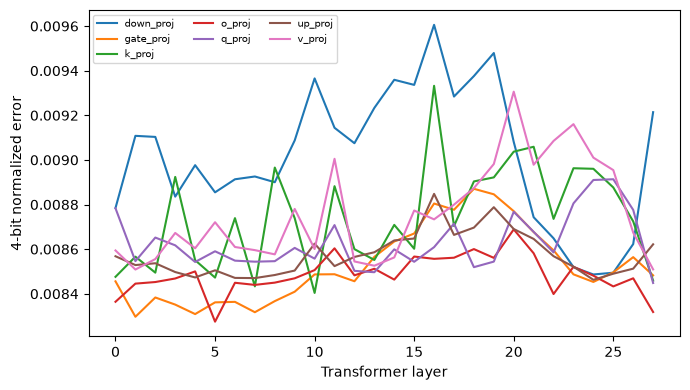

In [44]:
plt.figure(figsize=(7, 4))
for projection, group in q4.groupby("projection"):
    plt.plot(group.layer, group.error, label=projection)
plt.xlabel("Transformer layer")
plt.ylabel("4-bit normalized error")
plt.legend(fontsize=7, ncol=3)
save_figure("layer_error")

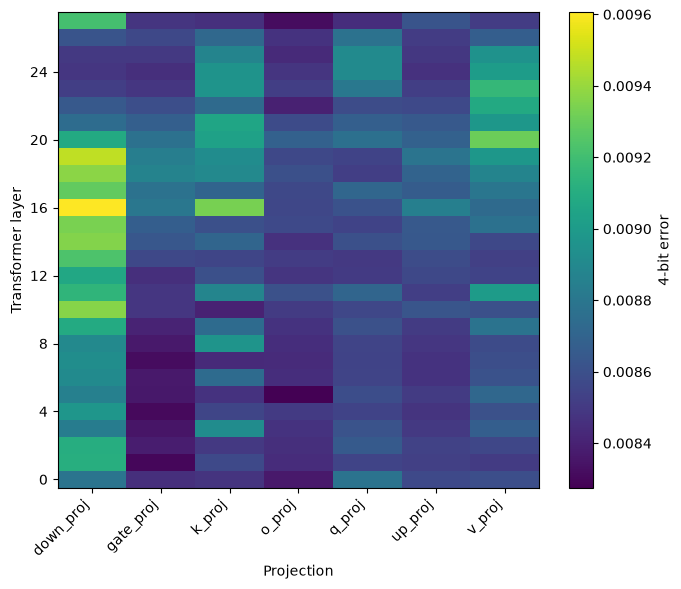

In [45]:
heat = q4.pivot(index="layer", columns="projection", values="error")
plt.figure(figsize=(7, 6))
plt.imshow(heat, aspect="auto", origin="lower")
plt.xticks(range(len(heat.columns)), heat.columns, rotation=45, ha="right")
plt.yticks(range(0, len(heat), 4), heat.index[::4])
plt.xlabel("Projection")
plt.ylabel("Transformer layer")
plt.colorbar(label="4-bit error")
save_figure("sensitivity_heatmap")

## 8. ShiftQ Allocation
Greedily reduce $E_i(b)[1-0.5r/(r+16)]$ per added byte.
The rank term is a heuristic; the budget includes packed weights, metadata, unchanged parameters and FP32 adapters.

In [46]:
BIT_CHOICES = [b for b in [3, 4, 6] if b in SUPPORTED]
RANK_CHOICES = [4, 8, 16, 32]
RANK_WEIGHT, ADAPTER_BYTES = 0.5, 4
names = list(shapes)
quant_cost = {(row.name, row.bits): int(row.bytes) for row in scores.itertuples()}
errors = scores.pivot(index="name", columns="bits", values="error")

In [47]:
del modules, projections, moments
quantize(model)
FIXED_BYTES = storage_bytes(model) - sum(quant_cost[n, 4] for n in names)
del model
clean_memory()

In [48]:
def layer_cost(name, bits, rank):
    return quant_cost[name, bits] + ADAPTER_BYTES * rank * sum(shapes[name])

def policy_cost(policy):
    return FIXED_BYTES + sum(layer_cost(n, *pair) for n, pair in policy.items())

def uniform_policy(bits=4, rank=16):
    return {name: (bits, rank) for name in names}

In [49]:
def proxy(name, pair, error_table):
    bits, rank = pair
    return error_table.loc[name, bits] * (1 - RANK_WEIGHT * rank / (rank + 16))

BUDGET = policy_cost(uniform_policy())
print("Storage budget (MB):", BUDGET / 1e6)

Storage budget (MB): 375.742464


In [50]:
def upgrades(policy, bit_choices, rank_choices):
    for name, (bits, rank) in policy.items():
        pairs = [(b, rank) for b in bit_choices if b > bits]
        pairs += [(bits, r) for r in rank_choices if r > rank]
        for pair in pairs:
            cost = layer_cost(name, *pair) - layer_cost(name, bits, rank)
            yield name, pair, cost

In [51]:
def best_upgrade(policy, table, bit_choices, rank_choices):
    remaining, choices = BUDGET - policy_cost(policy), []
    for name, pair, cost in upgrades(policy, bit_choices, rank_choices):
        gain = proxy(name, policy[name], table) - proxy(name, pair, table)
        if 0 < cost <= remaining and gain > 0:
            choices.append((gain / cost, name, pair))
    return max(choices) if choices else None

In [52]:
def allocate(table, bit_choices=BIT_CHOICES, rank_choices=RANK_CHOICES):
    policy = uniform_policy(min(bit_choices), min(rank_choices))
    assert policy_cost(policy) <= BUDGET
    while choice := best_upgrade(policy, table, bit_choices, rank_choices):
        _, name, pair = choice
        policy[name] = pair
    return policy

In [53]:
policies = {"uniform4_r16": uniform_policy(), "shiftq": allocate(errors),
            "adaptive_bits": allocate(errors, rank_choices=[16]),
            "adaptive_rank": allocate(errors, bit_choices=[4])}
for name, policy in policies.items():
    assert policy_cost(policy) <= BUDGET
    save_json(OUT / f"{name}_allocation.json", policy)
allocation = pd.DataFrame(policies["shiftq"], index=["bits", "rank"]).T.join(shape_table)
allocation.to_csv(OUT / "allocation.csv")

In [54]:
print("Bit/rank counts:", allocation[["bits", "rank"]].value_counts().to_dict())
print("Unused bytes:", BUDGET - policy_cost(policies["shiftq"]))
print("Heterogeneous bits:", allocation.bits.nunique() > 1)
print("Heterogeneous ranks:", allocation["rank"].nunique() > 1)
display(allocation.head(7))

Bit/rank counts: {(4, 4): 103, (6, 4): 85, (4, 8): 8}
Unused bytes: 0
Heterogeneous bits: True
Heterogeneous ranks: True


,bits,rank,output,input,layer,projection
model.layers.27.mlp.up_proj,4,4,3072,1024,27,up_proj
model.layers.27.mlp.down_proj,4,4,1024,3072,27,down_proj
model.layers.27.mlp.gate_proj,4,4,3072,1024,27,gate_proj
model.layers.27.self_attn.o_proj,4,4,1024,2048,27,o_proj
model.layers.27.self_attn.v_proj,6,4,1024,1024,27,v_proj
model.layers.27.self_attn.k_proj,6,4,1024,1024,27,k_proj
model.layers.27.self_attn.q_proj,4,4,2048,1024,27,q_proj


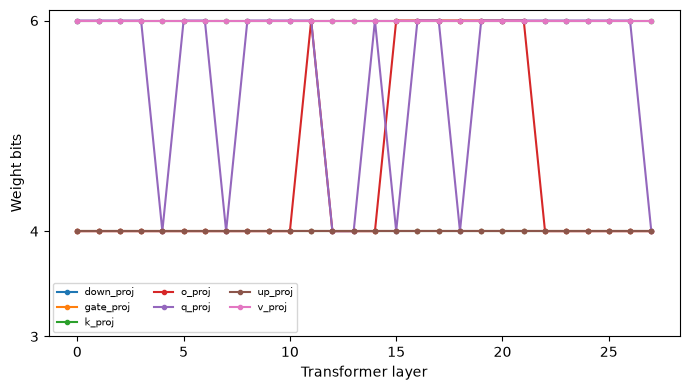

In [55]:
fig, ax = plt.subplots(figsize=(7, 4))
for projection, group in allocation.groupby("projection"):
    ax.plot(group.layer, group.bits, ".-", label=projection)
ax.set(xlabel="Transformer layer", ylabel="Weight bits", yticks=BIT_CHOICES)
ax.legend(fontsize=7, ncol=3)
fig.tight_layout()
fig.savefig(FIG / "precision_allocation.png", dpi=160)
plt.show()

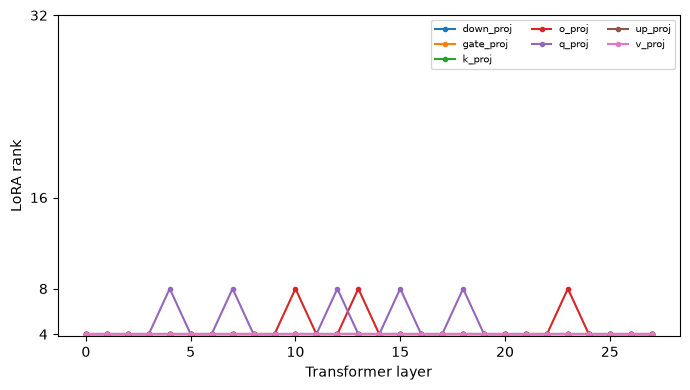

In [56]:
fig, ax = plt.subplots(figsize=(7, 4))
for projection, group in allocation.groupby("projection"):
    ax.plot(group.layer, group["rank"], ".-", label=projection)
ax.set(xlabel="Transformer layer", ylabel="LoRA rank", yticks=RANK_CHOICES)
ax.legend(fontsize=7, ncol=3)
fig.tight_layout()
fig.savefig(FIG / "rank_allocation.png", dpi=160)
plt.show()

## 9. Mixed-Precision Model
Use a per-module MLX predicate. Non-target weights remain 4-bit.

In [57]:
def check_bits(model, policy):
    modules = dict(model.named_modules())
    for name, (bits, _) in policy.items():
        layer = modules[name]
        assert isinstance(layer, nn.QuantizedLinear)
        assert layer.bits == bits and layer.group_size == GROUP_SIZE
    output = model(mx.array(data["validation"][:1, :-1]))
    assert mx.all(mx.isfinite(output)).item(), "Non-finite output"

In [58]:
model = fresh_model()
quantize(model, {n: b for n, (b, r) in policies["shiftq"].items()})
check_bits(model, policies["shiftq"])
print("Mixed base tensors (MB):", storage_bytes(model) / 1e6)

Mixed base tensors (MB): 365.256704


## 10. Adaptive LoRA
Insert a separate rank for each projection. Keep FP32 adapters and the same effective multiplier across ranks.

In [59]:
def insert_lora(model, policy):
    model.freeze()
    modules = dict(model.named_modules())
    replacements = [(n, LoRALinear.from_base(modules[n], r=rank, scale=LORA_SCALE))
                    for n, (_, rank) in policy.items()]
    model.update_modules(tree_unflatten(replacements))
    mx.eval(model.parameters())

In [60]:
def check_shapes(model, policy):
    modules = dict(model.named_modules())
    for name, (_, rank) in policy.items():
        layer, (output, input) = modules[name], shapes[name]
        assert layer.lora_a.shape == (input, rank)
        assert layer.lora_b.shape == (rank, output)
        assert layer.lora_a.dtype == layer.lora_b.dtype == mx.float32

In [61]:
def check_adapters(model, policy):
    check_shapes(model, policy)
    params = dict(tree_flatten(model.trainable_parameters()))
    expected = {n + suffix for n in policy for suffix in [".lora_a", ".lora_b"]}
    assert set(params) == expected, "Unexpected trainable parameters"
    count = sum(value.size for value in params.values())
    assert count == sum(rank * sum(shapes[n]) for n, (_, rank) in policy.items())
    assert storage_bytes(model) == policy_cost(policy), "Storage mismatch"
    return count

In [62]:
insert_lora(model, policies["shiftq"])
print("Trainable parameters:", check_adapters(model, policies["shiftq"]))
del model
clean_memory()

Trainable parameters: 2621440


## 11. Fine-Tuning
Reload the base checkpoint for every run. Use identical data order, update counts and optimizer settings; evaluate the final step.

In [63]:
def batch_order(seed):
    rng = np.random.default_rng(seed)
    count = TRAIN_STEPS * GRAD_ACCUM * BATCH_SIZE
    order = np.concatenate([rng.permutation(len(data["train"]))
                            for _ in range((count + len(data["train"]) - 1) // len(data["train"]))])
    return order[:count].reshape(TRAIN_STEPS, GRAD_ACCUM, BATCH_SIZE)

In [64]:
def accumulate(model, value_and_grad, indices):
    gradients, losses = None, []
    for batch_ids in indices:
        loss, grad = value_and_grad(model, mx.array(data["train"][batch_ids]))
        gradients = grad if gradients is None else tree_map(lambda a, b: a + b, gradients, grad)
        mx.eval(gradients, loss)
        losses.append(loss.item())
    assert np.isfinite(losses).all(), "Non-finite training loss"
    return float(np.mean(losses)), tree_map(lambda x: x / GRAD_ACCUM, gradients)

In [65]:
def train_update(model, optimizer, value_and_grad, indices):
    model.train()
    mx.reset_peak_memory()
    start = time.perf_counter()
    loss, gradients = accumulate(model, value_and_grad, indices)
    optimizer.update(model, gradients)
    mx.eval(model.parameters(), optimizer.state)
    mx.synchronize()
    return loss, time.perf_counter() - start, mx.get_peak_memory() / 1e9

In [66]:
def log_step(model, history, folder, step, loss, seconds=0, peak=0):
    val = evaluate(model, data["validation"]) if step % 5 == 0 or step == TRAIN_STEPS else None
    history.append(dict(step=step, train_nll=loss, validation_nll=val,
                        seconds=seconds, peak_gb=peak))
    pd.DataFrame(history).to_csv(folder / "losses.csv", index=False)

In [67]:
def finish_training(model, folder, history):
    params = dict(tree_flatten(model.trainable_parameters()))
    mx.save_safetensors(str(folder / "adapter.safetensors"), params)
    return dict(training_time_s=sum(row["seconds"] for row in history),
                training_peak_gb=max(row["peak_gb"] for row in history))

In [68]:
def fit(model, seed, folder):
    optimizer, history = optim.Adam(learning_rate=LEARNING_RATE), []
    value_and_grad = nn.value_and_grad(model, loss_fn)
    log_step(model, history, folder, 0, None)
    for step, indices in enumerate(tqdm(batch_order(seed), desc=folder.name), 1):
        stats = train_update(model, optimizer, value_and_grad, indices)
        log_step(model, history, folder, step, *stats)
    return finish_training(model, folder, history)

In [69]:
def train_with_checkpoint(model, seed, folder):
    block_type = type(model.layers[0])
    original = block_type.__call__
    try:
        if CHECKPOINT:
            grad_checkpoint(model.layers[0])
        return fit(model, seed, folder)
    finally:
        block_type.__call__ = original

In [70]:
def prepare_run(policy, seed):
    assert policy_cost(policy) <= BUDGET
    model = fresh_model()
    quantize(model, {name: pair[0] for name, pair in policy.items()})
    check_bits(model, policy)
    mx.random.seed(seed)
    insert_lora(model, policy)
    check_adapters(model, policy)
    return model

In [71]:
def allocation_metrics(model, policy):
    weights = sum(m * k for m, k in shapes.values())
    return dict(trainable_params=check_adapters(model, policy), budget_bytes=BUDGET,
        allocated_bytes=policy_cost(policy), budget_gap_pct=100 * (1 - policy_cost(policy) / BUDGET),
        projection_bpw=sum(shapes[n][0] * shapes[n][1] * b for n, (b, r) in policy.items()) / weights)

In [72]:
def run_experiment(name, policy, seed):
    folder = OUT / f"{name}_{seed}"
    folder.mkdir(parents=True, exist_ok=True)
    save_json(folder / "allocation.json", policy)
    model = prepare_run(policy, seed)
    metrics = train_with_checkpoint(model, seed, folder)
    record(name, seed, dict(**metrics, **measure(model), **allocation_metrics(model, policy)))
    del model
    clean_memory()

## 12. Baseline Comparisons
FAST_MODE trains two methods. Full mode adds bit-only, rank-only and random controls for two seeds.

In [73]:
groups = {}
for name in names:
    groups.setdefault(shapes[name], []).append(name)

def shuffled_policy(policy, seed):
    rng, shuffled = np.random.default_rng(seed), dict(policy)
    for group in groups.values():
        shuffled.update(zip(group, [policy[n] for n in rng.permutation(group)]))
    return shuffled

In [74]:
comparison_names = ["uniform4_r16", "shiftq"]
if not FAST_MODE:
    comparison_names += ["adaptive_bits", "adaptive_rank", "random"]
for seed in SEEDS:
    for name in comparison_names:
        policy = shuffled_policy(policies["shiftq"], seed) if name == "random" else policies[name]
        run_experiment(name, policy, seed)

random_43: 100%|██████████| 20/20 [00:33<00:00,  1.68s/it]


## 13. Evaluation
Latency is a synchronized forward pass without a KV cache, not decode speed. Training peaks exclude setup and validation.

In [75]:
metrics = pd.DataFrame(results)
columns = ["method", "seed", "validation_ppl", "test_ppl", "ag_test_ppl", "model_mb",
           "loaded_mlx_gb", "inference_peak_gb", "training_peak_gb", "trainable_params",
           "latency_ms", "training_time_s", "effective_bpw"]
display(metrics[columns].round(4))
metrics.to_csv(OUT / "metrics.csv", index=False)

,method,seed,validation_ppl,test_ppl,ag_test_ppl,model_mb,loaded_mlx_gb,inference_peak_gb,training_peak_gb,trainable_params,latency_ms,training_time_s,effective_bpw
0,unquantized,42,28.7607,25.2444,33.1511,1192.0998,1.1921,1.8119,NaN,0,53.7920,NaN,16.0000
1,uniform_3bit,42,98.4093,82.7257,167.4845,260.8742,0.2609,0.9231,NaN,0,52.9560,NaN,3.5014
2,uniform_4bit,42,36.4721,31.4051,44.1192,335.3723,0.3354,0.9976,NaN,0,52.6818,NaN,4.5013
3,uniform_6bit,42,29.3761,25.7194,33.8172,484.3684,0.4844,1.1545,NaN,0,53.5474,NaN,6.5010
4,uniform_8bit,42,28.8993,25.3359,33.3516,633.3645,0.6334,1.2773,NaN,0,52.7101,NaN,8.5008
5,uniform4_r16,42,24.8295,21.3064,47.6948,375.7425,0.3769,0.9521,1.2524,10092544,62.7899,16.0647,5.0431
6,shiftq,42,24.4680,21.1081,42.6672,375.7425,0.3769,0.9443,1.1575,2621440,62.7859,15.9811,5.0431
7,adaptive_bits,42,24.8295,21.3064,47.6948,375.7425,0.3769,0.9521,1.2524,10092544,62.5981,16.8850,5.0431
8,adaptive_rank,42,25.0545,21.5341,48.7322,375.7425,0.3769,0.9521,1.2520,10092544,62.7951,15.9626,5.0431
9,random,42,24.4425,20.9512,42.4583,375.7425,0.3769,0.9444,1.1578,2621440,62.6345,15.8959,5.0431


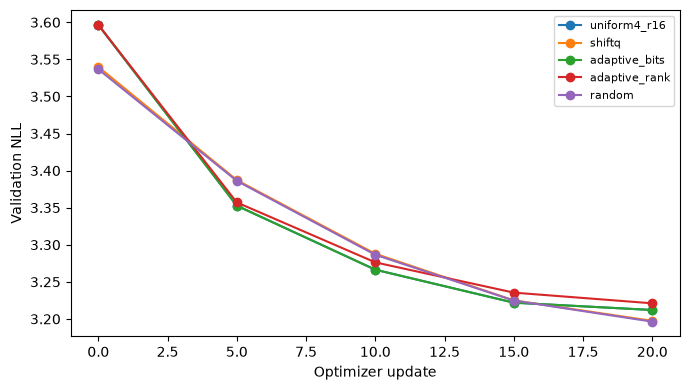

In [76]:
plt.figure(figsize=(7, 4))
for name in comparison_names:
    history = pd.read_csv(OUT / f"{name}_{SEED}" / "losses.csv").dropna(subset=["validation_nll"])
    plt.plot(history.step, history.validation_nll, "o-", label=name)
plt.xlabel("Optimizer update")
plt.ylabel("Validation NLL")
plt.legend(fontsize=8)
save_figure("validation_curves")

## 14. Ablation Studies
Random and fixed controls rearrange ShiftQ pairs within equal-shape groups, preserving storage and adapter counts.

In [77]:
def fixed_policy(policy):
    fixed = dict(policy)
    for group in groups.values():
        ordered = sorted(group, key=lambda n: (shape_table.loc[n, "layer"], n))
        fixed.update(zip(ordered, sorted((policy[n] for n in group), reverse=True)))
    return fixed

policies["fixed"] = fixed_policy(policies["shiftq"])
assert policy_cost(policies["fixed"]) == policy_cost(policies["shiftq"])

In [78]:
if RUN_ABLATIONS:
    for rank in [4, 8]:
        policies[f"uniform4_r{rank}"] = uniform_policy(rank=rank)
    for seed in SEEDS:
        for name in ["uniform4_r4", "uniform4_r8", "fixed"]:
            run_experiment(name, policies[name], seed)
else:
    print("Rank, fixed-policy and additional bitwidth ablations are ready; skipped in FAST_MODE.")

fixed_43: 100%|██████████| 20/20 [00:32<00:00,  1.65s/it]


Calibration shift uses activation-weighted error from WikiText or AG News training text. Weight-only scores cannot change with calibration text.

In [79]:
if RUN_SHIFT:
    for domain in ["wiki", "ag"]:
        table = scores.pivot(index="name", columns="bits", values=domain)
        policies[f"shiftq_{domain}"] = allocate(table)
    changed = sum(policies["shiftq_wiki"][n] != policies["shiftq_ag"][n] for n in names)
    save_json(OUT / "calibration_shift.json", dict(changed=changed, total=len(names)))
    print("Changed bit/rank pairs:", changed, "/", len(names))

Changed bit/rank pairs: 2 / 196


In [80]:
if RUN_SHIFT:
    for seed in SEEDS:
        for name in ["shiftq_wiki", "shiftq_ag"]:
            run_experiment(name, policies[name], seed)
else:
    print("Calibration-shift runs skipped in FAST_MODE.")

shiftq_ag_43: 100%|██████████| 20/20 [00:33<00:00,  1.65s/it]


In [81]:
metrics = pd.DataFrame(results)
summary = metrics.groupby("method").agg(ppl=("test_ppl", "mean"), sd=("test_ppl", "std"),
    model_mb=("model_mb", "mean"), peak_gb=("training_peak_gb", "mean"),
    trainable_params=("trainable_params", "mean"), latency_ms=("latency_ms", "mean"),
    seeds=("seed", "nunique"))
summary.to_csv(OUT / "summary.csv")

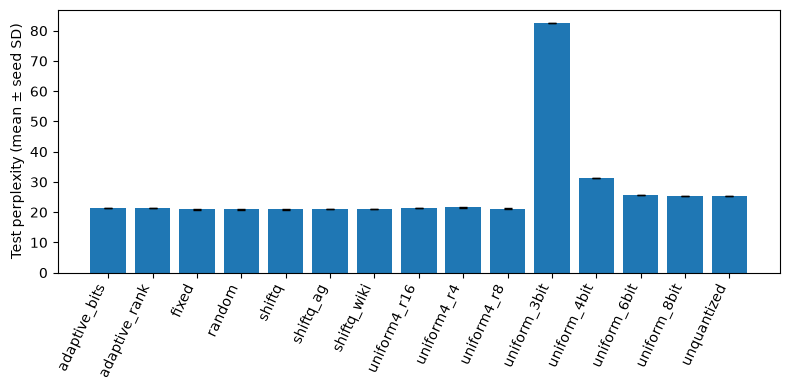

In [82]:
plt.figure(figsize=(8, 4))
plt.bar(summary.index, summary.ppl, yerr=summary.sd.fillna(0), capsize=3)
plt.ylabel("Test perplexity (mean ± seed SD)")
plt.xticks(rotation=65, ha="right")
save_figure("ablation_comparison")

## 15. Results
Report measured size gaps; a shared ceiling is not exact equality. Seed SD is descriptive, not a confidence interval.

In [83]:
display(summary.round(3))
reference = metrics.query("method == 'uniform4_r16'").set_index("seed")
relative = metrics[metrics.seed.isin(reference.index)].copy()
for key in ["test_ppl", "model_mb", "training_peak_gb", "trainable_params", "latency_ms"]:
    baseline = relative.seed.map(reference[key])
    relative[key + "_change_pct"] = 100 * (relative[key] / baseline - 1)
relative.to_csv(OUT / "relative_to_uniform4_r16.csv", index=False)
display(relative[["method", "seed", "test_ppl_change_pct", "model_mb_change_pct",
                  "trainable_params_change_pct", "budget_gap_pct"]].round(3))

,ppl,sd,model_mb,peak_gb,trainable_params,latency_ms,seeds
method,,,,,,,
adaptive_bits,21.275,0.044,375.742,1.252,10092544.0,66.165,2
adaptive_rank,21.495,0.055,375.742,1.252,10092544.0,63.747,2
fixed,20.932,0.100,375.742,1.158,2621440.0,62.670,2
random,20.920,0.045,375.742,1.158,2621440.0,62.663,2
shiftq,21.016,0.131,375.742,1.157,2621440.0,63.299,2
shiftq_ag,21.052,0.006,375.742,1.157,2588672.0,62.891,2
shiftq_wiki,21.039,0.045,375.742,1.158,2588672.0,62.705,2
uniform4_r16,21.275,0.044,375.742,1.252,10092544.0,62.721,2
uniform4_r4,21.640,0.097,345.465,1.126,2523136.0,62.634,2


,method,seed,test_ppl_change_pct,model_mb_change_pct,trainable_params_change_pct,budget_gap_pct
0,unquantized,42,18.482,217.265,-100.000,NaN
1,uniform_3bit,42,288.266,-30.571,-100.000,NaN
2,uniform_4bit,42,47.397,-10.744,-100.000,NaN
3,uniform_6bit,42,20.712,28.910,-100.000,NaN
4,uniform_8bit,42,18.912,68.563,-100.000,NaN
5,uniform4_r16,42,0.000,0.000,0.000,0.000
6,shiftq,42,-0.931,0.000,-74.026,0.000
7,adaptive_bits,42,0.000,0.000,0.000,0.000
8,adaptive_rank,42,1.069,0.000,0.000,0.000
9,random,42,-1.667,0.000,-74.026,0.000


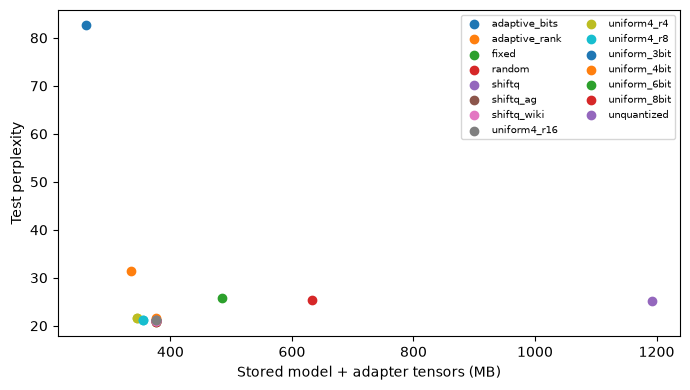

In [84]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, group in metrics.groupby("method"):
    ax.scatter(group.model_mb, group.test_ppl, label=name)
ax.set(xlabel="Stored model + adapter tensors (MB)", ylabel="Test perplexity")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIG / "perplexity_size.png", dpi=160)
plt.show()

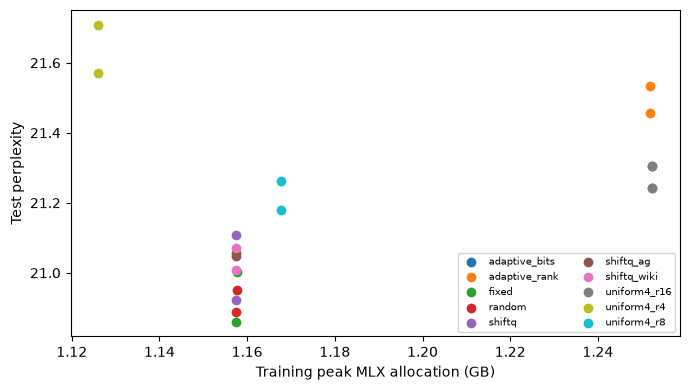

In [85]:
trained = metrics.dropna(subset=["training_peak_gb"])
fig, ax = plt.subplots(figsize=(7, 4))
for name, group in trained.groupby("method"):
    ax.scatter(group.training_peak_gb, group.test_ppl, label=name)
ax.set(xlabel="Training peak MLX allocation (GB)", ylabel="Test perplexity")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIG / "perplexity_peak_memory.png", dpi=160)
plt.show()

In [86]:
shift = relative.query("method == 'shiftq'")
ppl_change = float(shift.test_ppl_change_pct.mean())
size_change = float(shift.model_mb_change_pct.mean())
conclusion = (f"ShiftQ test PPL: {ppl_change:+.2f}%; tensor size: {size_change:+.2f}% "
              f"versus 4-bit/rank-16, across {len(shift)} seed(s). "
              "This does not establish general improvement.")
save_json(OUT / "conclusion.json", dict(text=conclusion, preliminary=FAST_MODE))
display(Markdown(conclusion))

ShiftQ test PPL: -1.22%; tensor size: +0.00% versus 4-bit/rank-16, across 2 seed(s). This does not establish general improvement.

## 16. Conclusion
Reviewed 1.7B run (20261018T211742253834Z): ShiftQ reduced test PPL by 2.52% versus 4-bit/rank-16, but matched random allocation closely. Rank-4 used 5.04% less storage with slightly lower mean PPL; a sensitivity advantage is not established.

Two seeds and 64 test sequences limit the evidence; later ablations also show about 1.02 GB extra active MLX memory. Next: check memory in a fresh kernel, then study validation-selected checkpoints with more seeds and held-out text.